In [12]:
# If required, install the libraries:
# pip install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

   Feature_1  Feature_2
0   0.830622  -0.432614
1   0.740349   0.825196
2   1.033435  -0.489607
3  -0.293316   0.964066
4   0.308208   1.093364
Dataset shape: (500, 2)


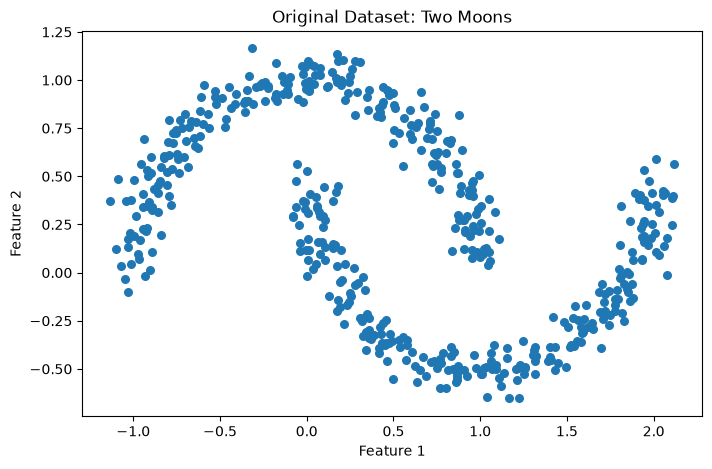

In [13]:
# Generate two crescent-shaped clusters
X, y_true = make_moons(
    n_samples=500,
    noise=0.07,
    random_state=42
)

# Create a DataFrame
df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])

print(df.head())
print("Dataset shape:", df.shape)

# Plot the original dataset
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], s=30)
plt.title("Original Dataset: Two Moons")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [14]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean after scaling:",
      X_scaled.mean(axis=0))

print("Standard deviation after scaling:",
      X_scaled.std(axis=0))

Mean after scaling: [-7.32747196e-18 -2.78443935e-16]
Standard deviation after scaling: [1. 1.]


In [15]:
# Initialize the model
dbscan = DBSCAN(
    eps=0.20,
    min_samples=5,
    metric="euclidean"
)

# Fit the model and predict cluster labels
labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the DataFrame
df["Cluster"] = labels

print(df.head(10))

# Count observations in each cluster
print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

# Number of clusters, excluding noise
n_clusters = len(set(labels) - {-1})

# Number of noise points
n_noise = np.sum(labels == -1)

print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", n_noise)

   Feature_1  Feature_2  Cluster
0   0.830622  -0.432614        0
1   0.740349   0.825196        1
2   1.033435  -0.489607        0
3  -0.293316   0.964066        1
4   0.308208   1.093364        1
5   1.259443  -0.488855        0
6   1.062777  -0.419966        0
7   0.041408   1.074225        1
8   0.607165   0.695734        1
9   1.776756  -0.168306        0

Cluster counts:
Cluster
-1      4
 0    247
 1    249
Name: count, dtype: int64

Number of clusters: 2
Number of noise points: 4


In [18]:
len(set(labels)- {-1})

2

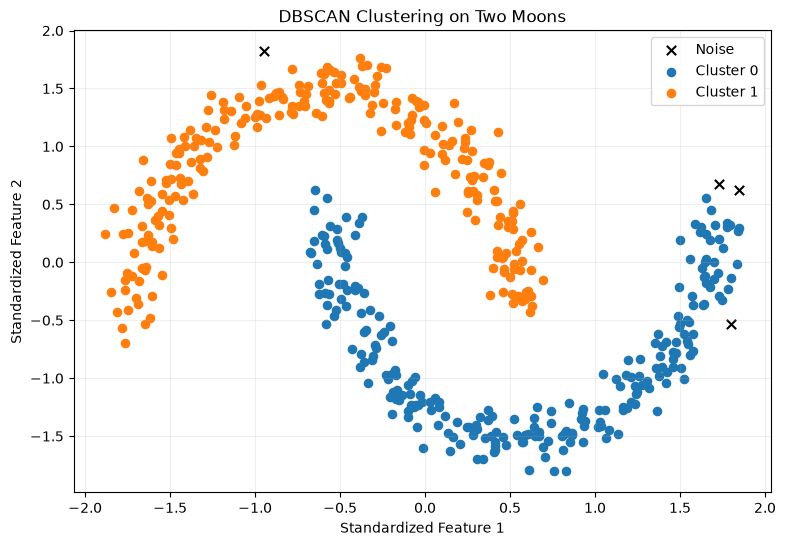

In [19]:
plt.figure(figsize=(9, 6))

unique_labels = sorted(set(labels))

for label in unique_labels:
    mask = labels == label

    if label == -1:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            c="black",
            marker="x",
            s=45,
            label="Noise"
        )
    else:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            s=35,
            label=f"Cluster {label}"
        )

plt.title("DBSCAN Clustering on Two Moons")
plt.xlabel("Standardized Feature 1")
plt.ylabel("Standardized Feature 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [21]:
# Exclude noise from the silhouette calculation
non_noise = labels != -1

labels_without_noise = labels[non_noise]
X_without_noise = X_scaled[non_noise]

n_valid_clusters = len(set(labels_without_noise))

if 2 <= n_valid_clusters < len(X_without_noise):
    score = silhouette_score(
        X_without_noise,
        labels_without_noise
    )
    print("Silhouette Score:", round(score, 4))
else:
    print(
        "Silhouette score is not defined for this "
        "number of non-noise clusters."
    )

Silhouette Score: 0.3869


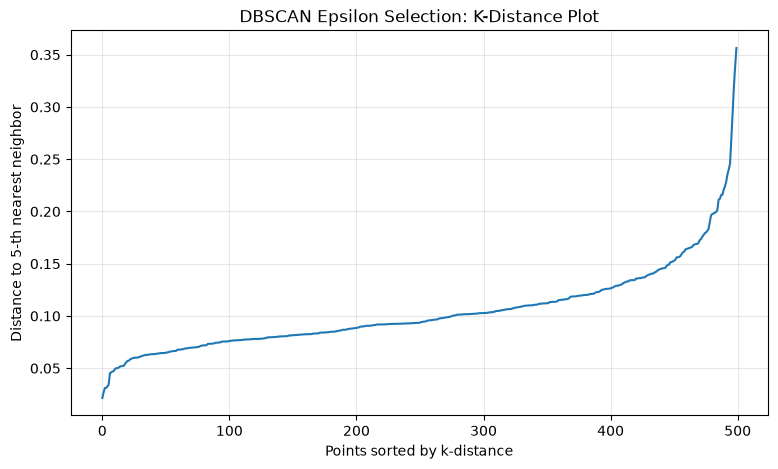

In [22]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    metric="euclidean"
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Distance to the min_samples-th nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by k-distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbor")
plt.title("DBSCAN Epsilon Selection: K-Distance Plot")
plt.grid(alpha=0.3)
plt.show()

Cluster
-1      7
 0    493
Name: count, dtype: int64


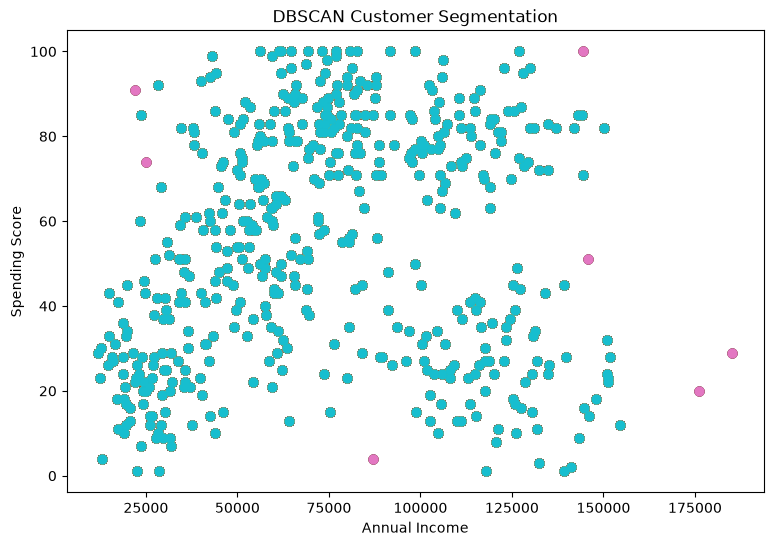

In [24]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

# Load customer dataset
df = pd.read_csv("customers.csv")

# Select relevant numerical features
features = [
    "Annual Income",
    "Spending Score"
]

# Remove missing observations for the selected features
customer_data = df[features].dropna()

# Standardize the features
scaler = StandardScaler()
X_customer = scaler.fit_transform(customer_data)

# Apply DBSCAN
model = DBSCAN(
    eps=0.35,
    min_samples=5
)

customer_labels = model.fit_predict(X_customer)

# Attach labels to retained observations
customer_data = customer_data.copy()
customer_data["Cluster"] = customer_labels

# Analyze cluster sizes
print(customer_data["Cluster"].value_counts().sort_index())

# Visualize the clusters in original units
plt.figure(figsize=(9, 6))

for label in sorted(customer_labels.tolist()):
    mask = customer_labels == label
    name = "Noise" if label == -1 else f"Cluster {label}"

    plt.scatter(
        customer_data.loc[mask, "Annual Income"],
        customer_data.loc[mask, "Spending Score"],
        s=40,
        label=name
    )

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("DBSCAN Customer Segmentation")
plt.show()

In [26]:
non_noise = customer_labels != -1

labels_without_noise = customer_labels[non_noise]
X_without_noise = X_scaled[non_noise]

n_valid_clusters = len(set(labels_without_noise))

if 2 <= n_valid_clusters < len(X_without_noise):
    score = silhouette_score(
        X_without_noise,
        labels_without_noise
    )
    print("Silhouette Score:", round(score, 4))
else:
    print(
        "Silhouette score is not defined for this "
        "number of non-noise clusters."
    )

Silhouette score is not defined for this number of non-noise clusters.
